<a href="https://colab.research.google.com/github/jyryu3161/chembigdata/blob/main/lec12_BBBP_improving_predictive_performance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BBBP 예측 (3): 샘플링과 Feature 처리로 모델 예측 성능 올리기

**학습 목표**: 저번 실습까지는 fingerprint를 그대로 넣고 모델만 바꾸었습니다.
이번 시간에는 **모델에 넣기 전 데이터를 어떻게 준비하는지**를 배웁니다.

| 강의 내용 | 이 노트북 |
|---|---|
| 불균형 데이터 | Undersampling · Oversampling · SMOTE |
| 스케일링 | 표준화 · 정규화 |
| feature selection | 분산 · 상관계수 · 지니 불순도 |
| feature engineering과 extraction | PCA |
| 모델 선택 | svm · bagging · boosting · voting |

6장에서는 1 ~ 5장에서 배운 내용을 골라 조합하고, 7장에서 제출 파일을 만듭니다.

**사용 데이터**: `train.csv`, `val.csv`, `test.csv`, `sample_submission.csv`
- `target=1`: BBB 투과 / `target=0`: BBB 비투과

## 0. 환경 준비

Colab에서 RDKit과 imbalanced-learn을 설치합니다.
`imbalanced-learn`은 Undersampling, Oversampling, SMOTE를 제공하는 패키지입니다.

In [ ]:
!pip install -q rdkit imbalanced-learn

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdFingerprintGenerator

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import (VarianceThreshold, SelectKBest, SelectFromModel, f_classif)
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier,
                              GradientBoostingClassifier, VotingClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, confusion_matrix)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline   # 샘플러를 넣을 수 있는 파이프라인

RDLogger.DisableLog("rdApp.*")
SEED = 42   # 같은 결과를 다시 재현하기 위한 숫자

## 준비. 데이터와 feature 만들기

아래 셀에서 파일 선택 창이 나타나면 네 파일을 한꺼번에 업로드합니다. 이미 Colab의 현재 폴더에 있다면 업로드를 건너뜁니다.

`train`에만 정답 `target`이 있습니다. 대회의 `val`과 `test`는 정답이 없으므로, 모델 비교에는 **train에서 따로 나눈 내부 검증 데이터**를 사용합니다.

In [ ]:
file_names = ["train.csv", "val.csv", "test.csv", "sample_submission.csv"]
missing = [name for name in file_names if not os.path.exists(name)]

if missing:
    from google.colab import files
    print("다음 파일을 업로드하세요:", missing)
    files.upload()

train = pd.read_csv("train.csv")
val = pd.read_csv("val.csv")
test = pd.read_csv("test.csv")
sample_sub = pd.read_csv("sample_submission.csv")

print("train:", train.shape, "val:", val.shape, "test:", test.shape)
print("제출 양식:", sample_sub.shape)
display(train.head())
print("정답별 개수")
print(train["target"].value_counts().sort_index())

다음 파일을 업로드하세요: ['train.csv', 'val.csv', 'test.csv', 'sample_submission.csv']


Saving val.csv to val.csv
Saving train.csv to train.csv
Saving test.csv to test.csv
Saving sample_submission.csv to sample_submission.csv
train: (1421, 3) val: (203, 2) test: (406, 2)
제출 양식: (609, 2)


,sample_id,SMILES,target
0,train_0001,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,0
1,train_0002,COC(=O)[C@@]1(O)CC[C@H]2C3CCC(=O)C4C(=O)C=CC4(...,1
2,train_0003,CN(C)CCc1ccccn1,1
3,train_0004,CC(C)NCC(O)COc1ccc(CC(N)=O)cc1,0
4,train_0005,O=C(Nc1ccc(O)cc1)C(Cl)(Cl)Cl,1


정답별 개수
target
0     341
1    1080
Name: count, dtype: int64


### 분자를 숫자 벡터로 바꾸기

모델은 숫자만 입력으로 받습니다. 그래서 SMILES(분자 구조 문자열)를 숫자로 바꿔야 합니다.
descriptor, fingerprint 두 가지 방법을 모두 만들어 두고 골라 씁니다.

**descriptor (물리화학적 성질)**
분자 하나의 성질을 숫자로 요약한 값입니다.

예를 들어
- `MolWt`: 분자량 (분자가 얼마나 무거운지)
- `MolLogP`: 기름에 녹는 정도 (클수록 기름에 잘 녹음)
- `TPSA`: 극성 표면적 (클수록 물에 잘 녹고, 세포막·BBB는 통과하기 어려움)
- `NumHDonors` / `NumHAcceptors`: 수소결합 주개 / 받개 수

한 분자가 이런 숫자 여러 개로 된 "한 줄"이 됩니다. 값의 단위·범위가 제각각이라 **스케일링이 필요**합니다.

**fingerprint (부분구조 유무)**
분자에 특정 부분구조(작은 조각)가 있으면 1, 없으면 0으로 표시한 긴 비트열입니다.
여기서는 2048칸을 쓰며, 전부 0/1이라 스케일링은 덜 중요하지만 **차원이 높습니다**.

| 이름 | 내용 | 특징 |
|---|---|---|
| **descriptor** | 분자량, LogP, TPSA 등 RDKit 물리화학적 성질 전체(200여 개) | 값의 단위와 범위가 제각각 → **스케일링이 필요** |
| **fingerprint** | Morgan fingerprint 2048비트 | 전부 0/1 → 스케일링은 덜 중요, 대신 **차원이 높음** |

In [ ]:
# 읽을 수 없는 SMILES가 있는지 확인합니다.
for name, data in [("train", train), ("val", val), ("test", test)]:
    data["mol"] = data["SMILES"].apply(Chem.MolFromSmiles)
    bad_rows = data.index[data["mol"].isna()].tolist()
    print(f"{name}: 변환 실패 {len(bad_rows)}개")
    if bad_rows:
        raise ValueError(f"{name}의 SMILES를 확인하세요. 데이터 행 번호: {bad_rows[:10]}")

train: 변환 실패 0개
val: 변환 실패 0개
test: 변환 실패 0개


In [ ]:
# descriptor = 분자 하나의 성질을 숫자로 요약한 값 (분자량, logP, TPSA 등)
DESC_FUNCS = dict(Descriptors.descList)   # {descriptor 이름: 계산 함수}
ALL_NAMES = list(DESC_FUNCS)              # descriptor 이름 전체

def make_descriptors(molecules):
    """분자 목록을 descriptor 표로 바꿉니다."""
    rows = []
    for mol in molecules:
        values = []
        for name in ALL_NAMES:
            values.append(DESC_FUNCS[name](mol))
        rows.append(values)
    return pd.DataFrame(rows, columns=ALL_NAMES).astype(float)

# train/val/test 모두 전체 descriptor를 계산합니다.
desc_train_all = make_descriptors(train["mol"])
desc_val_all   = make_descriptors(val["mol"])
desc_test_all  = make_descriptors(test["mol"])

# 어떤 분자에서는 값이 안 나와 NaN/무한대가 됩니다. 먼저 무한대를 NaN으로 바꿉니다.
desc_train_all = desc_train_all.replace([np.inf, -np.inf], np.nan)
desc_val_all   = desc_val_all.replace([np.inf, -np.inf], np.nan)
desc_test_all  = desc_test_all.replace([np.inf, -np.inf], np.nan)

# 0은 descriptor에서 의미 있는 값이라, NaN을 0으로 채우면 왜곡됩니다.
# 그래서 세 데이터 어디에도 NaN이 없는 descriptor만 남깁니다.
keep = desc_train_all.notna().all() & desc_val_all.notna().all() & desc_test_all.notna().all()
DESCRIPTORS = desc_train_all.columns[keep].tolist()

desc_train = desc_train_all[DESCRIPTORS]
desc_val   = desc_val_all[DESCRIPTORS]
desc_test  = desc_test_all[DESCRIPTORS]

print("descriptor:", len(ALL_NAMES), "개 중", len(DESCRIPTORS), "개 사용 /", desc_train.shape)

# descriptor가 많으므로 몇 개만 봅니다.
KEY_DESCRIPTORS = ["MolWt", "MolLogP", "TPSA", "NumHDonors", "NumHAcceptors", "NumRotatableBonds"]
display(desc_train[KEY_DESCRIPTORS].head(5).round(2))

descriptor: 217 개 중 209 개 사용 / (1421, 209)


,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds
0,197.19,0.05,103.78,4.0,4.0,3.0
1,376.45,1.43,100.90,2.0,6.0,1.0
2,150.22,1.19,16.13,0.0,2.0,3.0
3,266.34,0.45,84.58,3.0,4.0,8.0
4,254.50,2.70,49.33,2.0,2.0,1.0


In [ ]:
# fingerprint = 분자에 특정 부분구조(작은 조각)가 있으면 1, 없으면 0으로 표시한 2048칸 비트열
generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def make_fingerprints(molecules):
    """분자 목록을 fingerprint 표로 바꿉니다."""
    rows = []
    for mol in molecules:
        rows.append(generator.GetFingerprintAsNumPy(mol))
    return pd.DataFrame(np.array(rows)).astype(float)

fp_train = make_fingerprints(train["mol"])
fp_val   = make_fingerprints(val["mol"])
fp_test  = make_fingerprints(test["mol"])

print("fingerprint:", fp_train.shape)
display(fp_train.head(5))

fingerprint: (1421, 2048)


,0,1,2,3,4,5,6,7,8,9,...,2038,2039,2040,2041,2042,2043,2044,2045,2046,2047
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# ====== (3) 6장에서 골라 쓸 수 있게 묶어 둡니다 ======
FEATURES = {
    "descriptor":  (desc_train, desc_val, desc_test),
    "fingerprint": (fp_train, fp_val, fp_test),
}

y = train["target"].to_numpy() # 정답 열

print("feature 종류:", list(FEATURES.keys()))
print("descriptor:", desc_train.shape, "/ fingerprint:", fp_train.shape)

feature 종류: ['descriptor', 'fingerprint']
descriptor: (1421, 209) / fingerprint: (1421, 2048)


# 1장. 불균형 데이터

먼저 데이터가 얼마나 치우쳐 있는지 봅니다.
여기서는 **투과(1)가 다수 클래스, 비투과(0)가 소수 클래스**입니다.

,개수,비율(%)
0 (비투과),341,24.0
1 (투과),1080,76.0


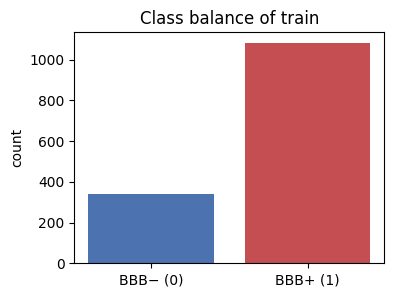

In [ ]:
counts = train["target"].value_counts().sort_index()
summary = pd.DataFrame({"개수": counts, "비율(%)": (counts / counts.sum() * 100).round(1)})
summary.index = ["0 (비투과)", "1 (투과)"]
display(summary)

plt.figure(figsize=(4, 3))
plt.bar(["BBB− (0)", "BBB+ (1)"], counts.values, color=["#4C72B0", "#C44E52"])
plt.ylabel("count")
plt.title("Class balance of train")
plt.show()

대회 `val.csv`와 구별하기 위해, 여기서 나누는 것을 내부 검증 데이터라고 부릅니다.

stratify=y는 두 그룹의 0과 1 비율을 비슷하게 유지합니다. 두 모델에 같은 데이터를 사용해 공정하게 비교합니다.

In [ ]:
# train을 내부 학습(80%) / 내부 검증(20%)으로 나눕니다.
# 나눈 데이터를 한번 정해두고 재사용하기 위해, 먼저 '행 번호'만 나눕니다.
idx_fit, idx_valid = train_test_split(
    np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED
)

# descriptor를 기본 feature X로 씁니다.
# .iloc로 idx_fit / idx_valid 위치에 해당하는 행만 꺼내 train / val로 나눕니다.
X_fit, X_valid = desc_train.iloc[idx_fit], desc_train.iloc[idx_valid]
y_fit, y_valid = y[idx_fit], y[idx_valid]

print("내부 학습:", len(X_fit), "개 / 내부 검증:", len(X_valid), "개")

내부 학습: 1136 개 / 내부 검증: 285 개


## 1-1. 데이터의 평가 지표


| 지표 | 의미 |
|---|---|
| **Accuracy** (정확도) | 전체 데이터 중 올바르게 예측한 비율  |
| **Precision** (정밀도) | 양성이라 예측한 것 중 실제 양성의 비율 |
| **Recall** (재현율) | 실제 양성 중 모델이 찾아낸 비율 |
| **F1-score** | Precision과 Recall의 조화평균. 둘 중 하나라도 낮으면 낮아진다 |
| **ROC-AUC** | ROC 곡선(FPR 대비 TPR) 아래 넓이. 임계값 변화에 따른 모델의 전반적인 분류 성능 (0.5 ~ 1.0) |
| **MCC** | 정답과 예측의 상관. -1 ~ +1 |

여섯 가지를 매번 적기 번거로우므로 함수 하나로 묶어 두고 계속 씁니다.

In [ ]:
def evaluate(y_true, prob, threshold=0.5):
    """불균형 데이터에서 봐야 할 지표 6개를 한 번에 계산합니다."""
    pred = (prob >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_true, pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "MCC": matthews_corrcoef(y_true, pred),
    }

## 1-2. Undersampling · Oversampling · SMOTE

| 방법 | 설명 | 단점 |
|---|---|---|
| **Undersampling** | 다수 클래스에서 일부만 무작위로 남긴다 | 데이터가 줄어 **정보 손실** |
| **Oversampling** | 소수 클래스 샘플을 **복제**해서 늘린다 | 같은 샘플이 반복되어 **과적합** |
| **SMOTE** | 소수 클래스 샘플과 그 최근접 이웃 사이에 **새 샘플을 합성** | 클래스가 겹친 영역에서 **잡음 샘플** 발생 |

> **샘플링은 학습 데이터에만 적용합니다.**
> 검증·평가 데이터에 적용하면 실제와 다른 분포에서 점수를 매기게 되어 결과를 믿을 수 없습니다.

In [ ]:
SAMPLERS = {
    "none":  None,
    "under": RandomUnderSampler(random_state=SEED),
    "over":  RandomOverSampler(random_state=SEED),
    "smote": SMOTE(random_state=SEED, k_neighbors=5),
}

# 샘플링 방법별로 train을 다시 뽑아, 클래스(0/1) 개수가 어떻게 바뀌는지 표로 봅니다.
resampled = {}
rows = []
for name in SAMPLERS:
    sampler = SAMPLERS[name]
    if sampler is None:    # "none"은 원본 그대로 사용
        X_res, y_res = X_fit, y_fit
    else:
        X_res, y_res = sampler.fit_resample(X_fit, y_fit)    # 샘플링하여 다시 구성한 X_res, y_res
    resampled[name] = (X_res, y_res)
    rows.append({
        "Sampling": name,
        "0 (비투과)": int((y_res == 0).sum()),
        "1 (투과)": int((y_res == 1).sum()),
        "Total": len(y_res),
    })

display(pd.DataFrame(rows).set_index("Sampling"))

,0 (비투과),1 (투과),Total
Sampling,,,
none,273,863,1136
under,273,273,546
over,863,863,1726
smote,863,863,1726


# 2장. 스케일링

## 표준화(standardization)와 정규화(normalization)

| | 결과 |
|---|---|
| **표준화** | 평균 0, 표준편차 1. 범위 제한 없음 → 이상치에 덜 민감 |
| **정규화 (Min-Max)** | 값이 [0, 1] 범위. 최솟값·최댓값을 쓰므로 **이상치에 민감** |

둘 다 **분포의 모양은 바꾸지 않고 축의 눈금만 바꿉니다.**

In [ ]:
SCALERS = {"none": None, "standard": StandardScaler(), "minmax": MinMaxScaler()}

# 변환에 쓰는 평균·표준편차는 '학습 데이터'에서만 계산합니다.
# descriptor는 이상치(아주 큰 값)가 있을 수 있어, 보통 standardization을 더 선호
scaler = StandardScaler().fit(X_fit)
X_fit_scaled = pd.DataFrame(scaler.transform(X_fit), columns=DESCRIPTORS)
X_valid_scaled = pd.DataFrame(scaler.transform(X_valid), columns=DESCRIPTORS)

# describe(): 각 열의 요약 통계(개수·평균·표준편차·최소/최대 등)를 한 번에 계산
compare = pd.concat([X_fit.describe().loc[["mean", "std"]].T,
                     X_fit_scaled.describe().loc[["mean", "std"]].T], axis=1)
compare.columns = ["변환 전 평균", "변환 전 표준편차", "변환 후 평균", "변환 후 표준편차"]
display(compare.loc[KEY_DESCRIPTORS].round(3))

,변환 전 평균,변환 전 표준편차,변환 후 평균,변환 후 표준편차
MolWt,354.352,144.400,0.0,1.0
MolLogP,2.345,2.041,0.0,1.0
TPSA,73.207,58.256,-0.0,1.0
NumHDonors,1.585,1.855,-0.0,1.0
NumHAcceptors,4.605,3.197,-0.0,1.0
NumRotatableBonds,4.328,3.224,0.0,1.0


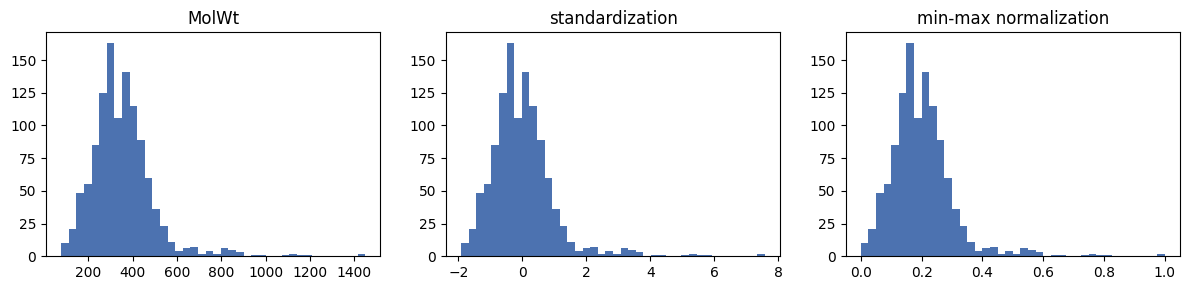

In [ ]:
# 분포의 '모양'은 그대로이고 x축 눈금만 바뀝니다.
minmax = MinMaxScaler().fit(X_fit)
column = DESCRIPTORS.index("MolWt")
views = [(X_fit["MolWt"].values, "MolWt"),
         (scaler.transform(X_fit)[:, column], "standardization"),
         (minmax.transform(X_fit)[:, column], "min-max normalization")]

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (values, title) in zip(axes, views):
    ax.hist(values, bins=40, color="#4C72B0")
    ax.set_title(title)
plt.tight_layout()
plt.show()

# 3장. 차원의 저주와 Feature selection

## 차원의 저주

차원(feature 수)이 늘어날수록, 공간을 채우는 데 필요한 데이터가 지수적으로 늘어납니다.
즉, feature가 많을수록 학습이 어려워집니다.

차원이 커지면 한 점에서 가장 가까운 점과 가장 먼 점의 거리 차이가 줄어듭니다. "가깝다 / 멀다"의 구분이 흐려져 거리를 기준으로 판단하는 모델(예: k-NN)의 성능이 떨어집니다.

그래서 쓸모없는 feature가 많으면 줄이는 것이 좋습니다.

## 용어 정리와 세 가지 방법론

| 표현 | 정의 |
|---|---|
| **Feature Selection** | 기존 피처에서 원하는 피처만 (변경하지 않고) 선택 |
| **Feature Engineering** | 도메인 지식을 사용하여 데이터에서 피처를 변형/생성 |
| **Feature Extraction** | 차원 축소 등 새로운 중요 피처를 추출 |

## Feature selection 대표 방법
##  3-1. 분산이 작은 feature 제거

모든 샘플에서 값이 같은 feature는 아무 정보가 없습니다.

fingerprint는 각 비트가 0 아니면 1이고, 2048비트 중 대부분은 거의 모든 분자에서 0입니다.

#### 얼마나 작은 분산을 버릴까?
0/1 값에서 1이 나오는 비율을 p라 하면 분산은 p × (1 - p)입니다.

예를 들어 “95% 이상의 분자에서 값이 같은 비트”를 버리고 싶다면,
1이 5%만 나오는 경우(p = 0.05)의 분산 0.05 × 0.95 = 0.0475를 기준(threshold)으로 씁니다.
→ 분산이 이보다 작은(= 더 안 변하는) 비트는 제거됩니다.

분산 기반 제거는 주로 **0/1 feature**에 쓰므로, 여기서는 2048비트 fingerprint를 대상으로 실습합니다.

> **주의** 표준화를 하면 모든 feature의 분산이 1이 되어 이 기준이 아무 의미가 없어집니다.
> 분산 기준은 **스케일링하기 전에**, 그리고 주로 **0/1 feature**에 씁니다.

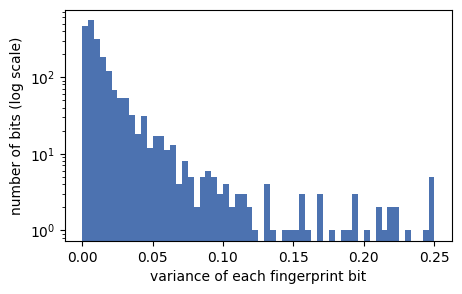

99% 이상 같은 값인 비트 제거 (threshold = 0.0099) → 2048개 중 867개 남음
95% 이상 같은 값인 비트 제거 (threshold = 0.0475) → 2048개 중 151개 남음
90% 이상 같은 값인 비트 제거 (threshold = 0.0900) → 2048개 중 62개 남음


In [ ]:
variances = fp_train.var()

plt.figure(figsize=(5, 3))
plt.hist(variances, bins=60, color="#4C72B0")
plt.yscale("log")  # 대부분 분산이 0 근처라, 개수를 로그 눈금으로 봅니다
plt.xlabel("variance of each fingerprint bit")
plt.ylabel("number of bits (log scale)")
plt.show()

for ratio in [0.99, 0.95, 0.90]:
    threshold = ratio * (1 - ratio)    # 분산 공식 p(1-p)
    selector = VarianceThreshold(threshold=threshold).fit(fp_train)
    n_left = selector.get_support().sum()    # 살아남은(분산이 threshold보다 큰) 비트 수
    percent = int(ratio * 100)
    print(f"{percent}% 이상 같은 값인 비트 제거 (threshold = {threshold:.4f}) → 2048개 중 {n_left}개 남음")

## 3-2. 상관계수: label과의 상관이 큰 feature 남기기

피어슨 상관계수는 두 변수가 얼마나 **직선 관계**에 가까운지를 -1 ~ 1로 나타냅니다.

$$r = \frac{\sum (X - \bar{X})(Y - \bar{Y})}{\sqrt{\sum (X-\bar{X})^2}\sqrt{\sum (Y-\bar{Y})^2}}$$

정답 `target`과 |r|이 큰 feature부터 남깁니다.

> 상관계수는 반드시 **학습 데이터의 정답만** 보고 계산해야 합니다 (데이터 누수).

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


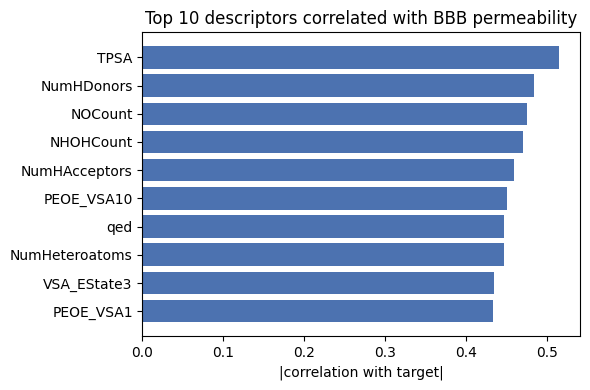

In [ ]:
# 각 feature와 정답(target) 사이의 피어슨 상관계수
label = pd.Series(y_fit, index=X_fit.index)

# 값이 일정한(분산 0) descriptor는 상관계수가 정의되지 않아 NaN이 됩니다.
# 선형 관계가 없다는 뜻이므로 0으로 둡니다.
# 상관의 방향(+/-)보다 절댓값(세기)이 더 중요하므로 abs()를 씁니다.
corr_scores = X_fit.corrwith(label).abs().fillna(0)

top = corr_scores.sort_values(ascending=False).head(10)

plt.figure(figsize=(6, 4))
plt.barh(top.index[::-1], top.values[::-1], color="#4C72B0")
plt.xlabel("|correlation with target|")
plt.title("Top 10 descriptors correlated with BBB permeability")
plt.tight_layout()
plt.show()

## 3-3. 지니 불순도 기반: 랜덤 포레스트 feature importance

**지니 불순도(Gini impurity)** 는 한 그룹 안에 클래스가 얼마나 섞여 있는지 나타냅니다.
그룹 내 한 클래스만 있으면 0(순수)이고, 2클래스가 반반 섞이면 최대 0.5입니다.

랜덤 포레스트는 어떤 feature로 데이터를 나눴을 때 지니 불순도가 줄어든 양을 그 feature의 기여로 기록합니다.

이 기여를 모은 것이 feature_importances_이고, 값이 클수록 중요한 feature입니다.

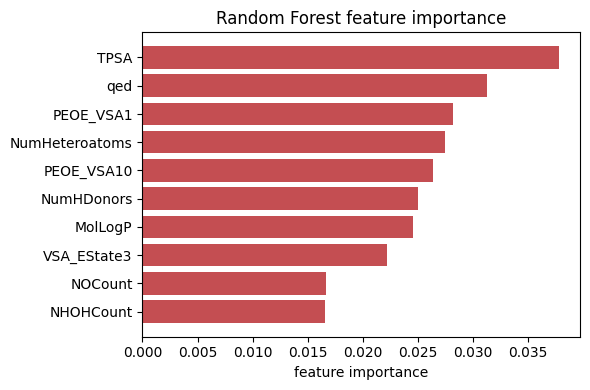

In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=SEED)
rf.fit(X_fit, y_fit)

importance = pd.Series(rf.feature_importances_, index=DESCRIPTORS)
top = importance.sort_values(ascending=False).head(10)

plt.figure(figsize=(6, 4))
plt.barh(top.index[::-1], top.values[::-1], color="#C44E52")
plt.xlabel("feature importance")
plt.title("Random Forest feature importance")
plt.tight_layout()
plt.show()

In [ ]:
# 상관계수로 매긴 순위와 importance로 매긴 순위를 나란히 비교합니다.
corr_rank = corr_scores.rank(ascending=False).astype(int)
imp_rank  = importance.rank(ascending=False).astype(int)

ranks = pd.DataFrame({"상관계수 순위": corr_rank, "importance 순위": imp_rank})
ranks = ranks.sort_values("importance 순위")

print("두 방법의 순위가 항상 같지는 않습니다:")
display(ranks.head(10))

두 방법의 순위가 항상 같지는 않습니다:


,상관계수 순위,importance 순위
TPSA,1,1
qed,7,2
PEOE_VSA1,10,3
NumHeteroatoms,8,4
PEOE_VSA10,6,5
NumHDonors,2,6
MolLogP,15,7
VSA_EState3,9,8
NOCount,3,9
NHOHCount,4,10


## 4장. Feature engineering과 extraction
## 4-1. Feature engineering: 도메인 지식으로 새 feature 만들기

강의의 대표 예는 **BMI = kg / m²** 입니다. 키와 몸무게 두 열을 **의미 있는 한 열**로 바꾼 것입니다.

descriptor도 SMILES로 표현된 분자 구조로부터 도메인 지식으로 뽑아낸 feature입니다.

## 4-2. Feature extraction: PCA

- **Feature selection**: 기존 feature 중 일부를 **그대로** 남김
- **Feature extraction**: 기존 feature를 조합해 더 낮은 차원으로 압축

PCA는 데이터의 **분산이 가장 큰 방향**을 PC1으로, PC1과 직교하면서 남은 분산이 가장 큰 방향을
PC2로... 이렇게 새 축을 찾습니다.

PC1에서부터 분산을 더한 누적값을 보고 정하는데, 누적 분산의 90% 이상이 되는 지점을 쓰거나, 곡선의 기울기가 완만해지는 지점(elbow) — 성분을 더 늘려도 정보가 거의 안 느는 곳 — 을 고릅니다.

> 단위가 다른 feature는 **반드시 표준화 후** PCA를 적용합니다.
> 그러지 않으면 분산이 큰 변수 쪽으로 주성분이 끌려갑니다.

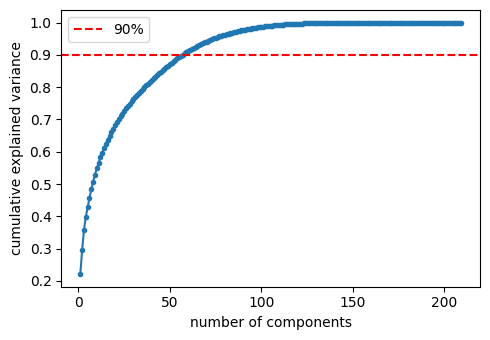

In [ ]:
pca = PCA(random_state=SEED).fit(X_fit_scaled)
cumulative = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(5, 3.5))
plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o", markersize=3)
plt.axhline(0.9, color="red", linestyle="--", label="90%")
plt.xlabel("number of components")
plt.ylabel("cumulative explained variance")
plt.legend()
plt.tight_layout()
plt.show()

## 4-3. 골라서 모델에 넣어 보기

위에서 본 방법들(분산 · 상관계수 · 중요도 · PCA)로 feature를 줄인 뒤, 같은 랜덤 포레스트로 성능을 비교합니다.
feature는 학습 데이터로만 고르고(fit_transform), 검증 데이터에는 고른 결과를 적용만 합니다(transform).


In [ ]:
selectors = {
    "none":       None,                                            # 그대로
    "variance":   VarianceThreshold(threshold=0.0),                # 분산 0(상수)인 feature만 제거
    "corr_label": SelectKBest(score_func=f_classif, k=100),        # 정답과 상관 큰 상위 100개
    "importance": SelectFromModel(
                      RandomForestClassifier(n_estimators=100, random_state=SEED), # 랜덤 포레스트 중요도 상위 100개
                      threshold=-np.inf, max_features=100),  # threshold보다 중요도가 높은 feature만 가장 높은 순서대로. threshold=-np.inf: 가장 작은 값, 즉 중요도 기준 없음.
    "pca":        PCA(n_components=100, random_state=SEED),  # 100개의 새 축으로 압축
}

# 방법별로 feature를 줄인 뒤, 같은 랜덤 포레스트로 성능을 비교합니다.
rows = []
for name in selectors:
    selector = selectors[name]
    if selector is None:                         # "none": 그대로 사용
        X_train_sel, X_valid_sel = X_fit, X_valid
    elif name == "pca":                          # PCA는 표준화한 입력을 씁니다
        X_train_sel = selector.fit_transform(X_fit_scaled)
        X_valid_sel = selector.transform(X_valid_scaled)
    else:                                        # variance · corr_label · importance
        X_train_sel = selector.fit_transform(X_fit, y_fit)
        X_valid_sel = selector.transform(X_valid)

    model = RandomForestClassifier(n_estimators=100, random_state=SEED)
    model.fit(X_train_sel, y_fit)
    prob = model.predict_proba(X_valid_sel)[:, 1]

    row = {"방법": name, "feature 수": X_train_sel.shape[1]}
    row.update(evaluate(y_valid, prob))
    rows.append(row)

display(pd.DataFrame(rows).set_index("방법").round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 61  74 156 161 173 174 205] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


,feature 수,Accuracy,Precision,Recall,F1,ROC-AUC,MCC
방법,,,,,,,
none,209,0.895,0.895,0.977,0.934,0.924,0.694
variance,202,0.888,0.894,0.968,0.929,0.911,0.672
corr_label,100,0.884,0.897,0.959,0.927,0.918,0.663
importance,100,0.902,0.906,0.972,0.938,0.909,0.716
pca,100,0.877,0.889,0.959,0.922,0.892,0.641


# 5장. 모델 선택

### SVM (서포트 벡터 머신)

두 클래스를 잘 분류하는 결정 경계(Decision boundary)를 찾는 모델입니다.
경계에 가장 가까운 점들(서포트 벡터)이 경계의 위치를 정합니다.

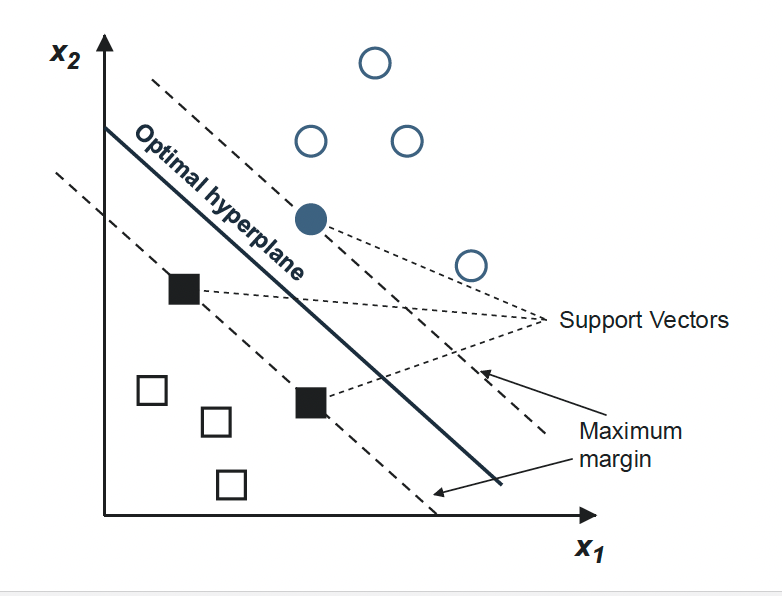

**주요 하이퍼파라미터**

- C: 클수록 오차를 덜 허용 → 경계가 복잡해지고 과적합 위험이 커집니다.

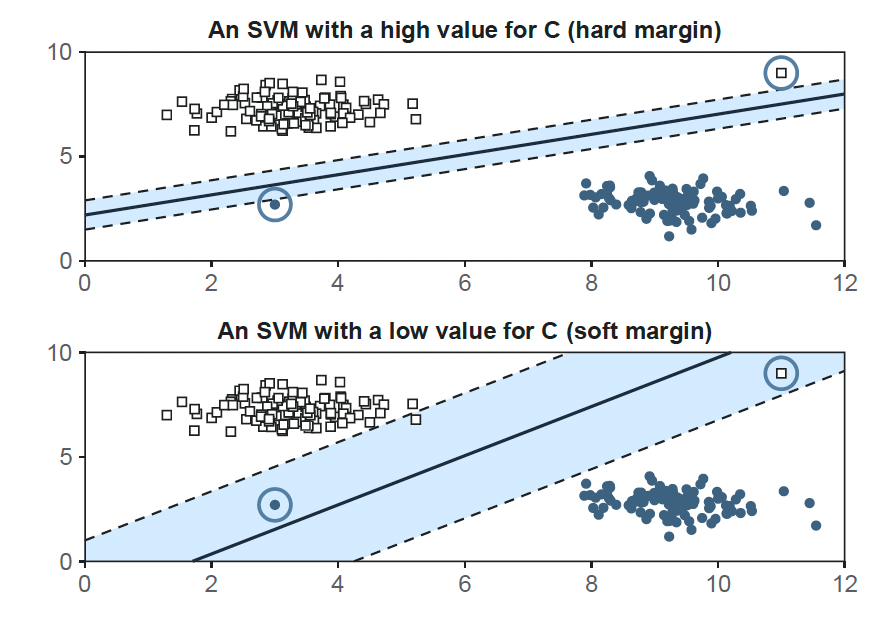

- gamma: RBF 커널의 파라미터로, 각 데이터 포인트의 영향이 미치는 범위를 정해 결정 경계를 얼마나 유연하게 그을 것인지 정해주는 파라미터

클수록 데이터에 많이 의존하여 경계가 구불구불 → 과적합 위험이 커집니다.

거리(간격)를 기준으로 하므로 스케일에 민감합니다 → 표준화 후 사용합니다.

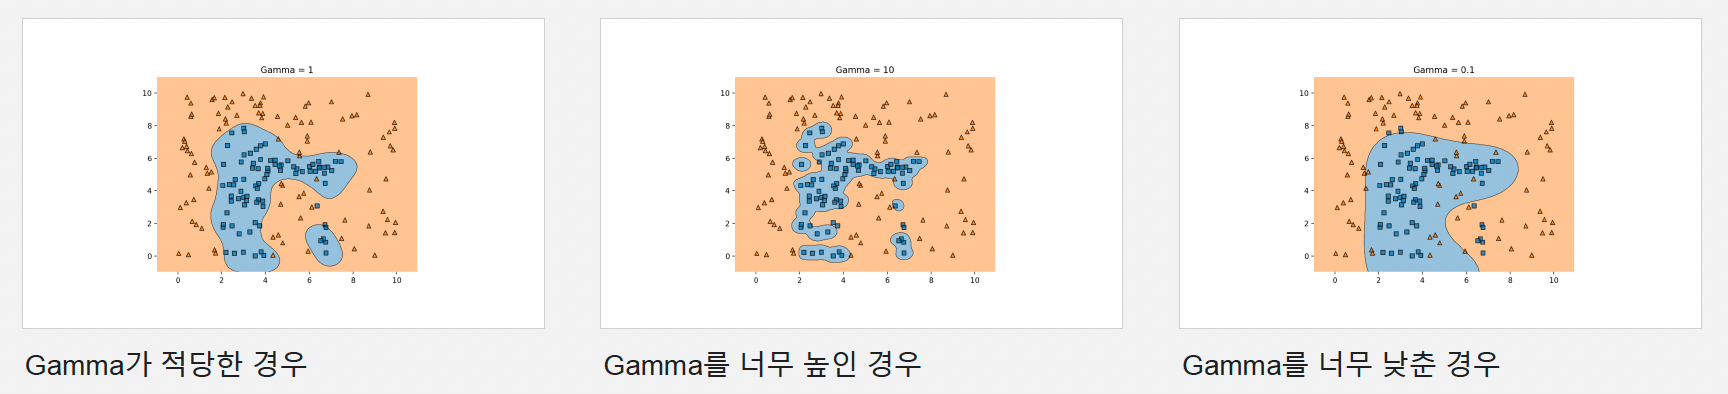

### 앙상블 학습
여러 모델을 함께 사용해 기존보다 성능을 더 올리는 방법입니다.

| 종류 | 설명 | 이 노트북 |
|---|---|---|
| **Bagging** | 데이터를 **복원 추출(bootstrap)** 해 여러 모델을 독립적으로 학습하고 결과를 합친다 | `bagging`, `random_forest` |
| **Boosting** | 앞 모델이 **틀린 데이터에 집중**하도록 모델을 차례로 추가한다 | `boosting` |
| **Voting** | **서로 다른 종류**의 모델을 같은 데이터로 학습하고 예측을 합친다 | `voting` |


**Bagging과 Random Forest의 차이**

Bagging은 데이터를 무작위로 복원 추출해 서로 다른 표본으로 나무를 여러 개 학습합니다.

Random Forest는 여기에 더해 feature도 일부만 무작위로 골라 학습합니다.

**Boosting 구현**

이 노트북은 sklearn의 `GradientBoostingClassifier`를 씁니다. 앞 모델의 잔차(오차)를 예측하도록 다음 나무를 추가하는 방식이며, sklearn에 내장돼 있어 추가 설치 없이 바로 쓸 수 있습니다.

실무에서는 더 빠르고 성능이 좋은 XGBoost / LightGBM을 주로 쓰지만, 별도 설치와 더 많은 하이퍼파라미터 튜닝이 필요합니다.

**Hard voting과 soft voting**
- **Hard voting**: 각 모델의 0/1 예측을 받아 **다수결**로 정합니다.
- **Soft voting**: 각 모델의 **확률을 평균**한 뒤 임계값으로 정합니다.

> 이 노트북은 **soft voting**을 씁니다. 각 모델의 확률을 평균하므로
> voting도 다른 모델처럼 확률과 ROC-AUC를 그대로 비교할 수 있습니다.
>
> Voting은 같은 알고리즘을 bootstrap 표본으로 여러 번 학습하는 Bagging과 다릅니다.

In [ ]:
MODELS = {
    # 단일 모델
    "knn":           KNeighborsClassifier(n_neighbors=5),
    "tree":          DecisionTreeClassifier(max_depth=10, random_state=SEED),
    "svm":           SVC(kernel="rbf", C=1.0, gamma="scale", # 기본 커널: rbf(radial basis function)
                         probability=True, random_state=SEED),
    # 앙상블
    "bagging":       BaggingClassifier(DecisionTreeClassifier(random_state=SEED),
                                       n_estimators=100, random_state=SEED),
    "random_forest": RandomForestClassifier(n_estimators=100, random_state=SEED),
    "boosting":      GradientBoostingClassifier(n_estimators=100, random_state=SEED), # Gradient Boosting: 나무가 이미 내장
}

# 원하는 모델로 투표 앙상블을 만듭니다.
estimators = [
    ("knn", KNeighborsClassifier(n_neighbors=5)),    # (이름, 모델)
    ("random_forest", RandomForestClassifier(n_estimators=100, random_state=SEED)),
    ("boosting", GradientBoostingClassifier(n_estimators=100, random_state=SEED)),
]

MODELS["soft_voting"] = VotingClassifier(estimators=estimators, voting="soft")  # 확률을 평균

In [ ]:
# 모두 같은 스케일링 조건(표준화)에서 비교합니다.
rows = []
for name in MODELS:
    model = MODELS[name]
    model.fit(X_fit_scaled, y_fit)
    prob = model.predict_proba(X_valid_scaled)[:, 1]

    row = {"모델": name}
    row.update(evaluate(y_valid, prob))
    rows.append(row)

display(pd.DataFrame(rows).set_index("모델").round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC,MCC
모델,,,,,,
knn,0.881,0.883,0.972,0.925,0.887,0.649
tree,0.849,0.895,0.908,0.902,0.772,0.579
svm,0.898,0.902,0.972,0.936,0.904,0.705
bagging,0.888,0.894,0.968,0.929,0.919,0.672
random_forest,0.891,0.894,0.972,0.932,0.924,0.683
boosting,0.877,0.889,0.959,0.922,0.910,0.641
soft_voting,0.888,0.890,0.972,0.930,0.933,0.672


# 6장. 설정을 골라서 돌려 보기

1 ~ 5장에서 배운 방법들을 모아, 아래 설정만 바꿔 가며 성능을 비교합니다.

**이름으로 고르는 것** (준비된 것 중 선택)
| 설정 | 고를 수 있는 값 |
|---|---|
| `feature` | descriptor · fingerprint |
| `scaling` | none · standard · minmax |
| `sampling` | none · under · over · smote |

**직접 정의하는 것** (하이퍼파라미터를 조절)
| 설정 | 예 |
|---|---|
| `selector` | `None` · `SelectKBest(f_classif, k=50)` · `PCA(n_components=50, random_state=SEED)` |
| `model` | `RandomForestClassifier(...)` · `KNeighborsClassifier(n_neighbors=5)` · … |

설정을 바꾸면 feature → 스케일링 → 샘플링 → feature 선택 → 모델 순서의 파이프라인이 만들어집니다.

(PCA를 selector로 쓸 때는 scaling="standard"와 함께 쓰세요.)

In [ ]:
# --- 고르는 것 ---
feature  = "descriptor"      # descriptor | fingerprint
scaling  = "standard"        # none | standard | minmax
sampling = "over"           # none | under | over | smote

# --- 직접 조절하는 것 ---
selector = None    # 안쓰려면 None
model = RandomForestClassifier(n_estimators=100, random_state=SEED) # 5장 참고

In [ ]:
# 고른 feature가 몇 개인지 확인합니다.
print("feature 종류:", feature, "/ feature 개수:", FEATURES[feature][0].shape[1])

feature 종류: descriptor / feature 개수: 209


In [ ]:
# 스케일링 → 샘플링 → feature 선택 → 모델
# 'none'으로 둔 단계는 건너뜁니다.
steps = []
if scaling != "none":
    steps.append(("scaler", SCALERS[scaling]))
if sampling != "none":
    steps.append(("sampler", SAMPLERS[sampling]))
if selector is not None:
    steps.append(("selector", selector))
steps.append(("model", model))

pipeline = Pipeline(steps)
print(pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('sampler', RandomOverSampler(random_state=42)),
                ('model', RandomForestClassifier(random_state=42))])


In [ ]:
X_train_all = FEATURES[feature][0]
X_fit = X_train_all.iloc[idx_fit]
X_valid = X_train_all.iloc[idx_valid]

pipeline.fit(X_fit, y_fit)
prob = pipeline.predict_proba(X_valid)[:, 1]

display(pd.Series(evaluate(y_valid, prob)).round(3).to_frame("내부 검증 점수"))

,내부 검증 점수
Accuracy,0.898
Precision,0.902
Recall,0.972
F1,0.936
ROC-AUC,0.915
MCC,0.705


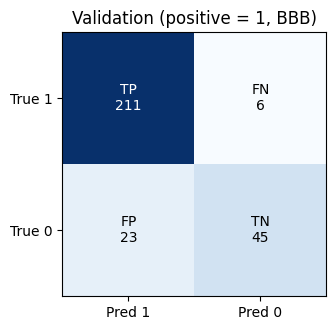

In [ ]:
def plot_confusion(y_true, prob, title, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    matrix = confusion_matrix(y_true, pred, labels=[1, 0])
    names = [["TP", "FN"], ["FP", "TN"]]

    plt.figure(figsize=(3.6, 3.4))
    plt.imshow(matrix, cmap="Blues")
    for i in range(2):
        for j in range(2):
            color = "white" if matrix[i, j] > matrix.max() / 2 else "black"
            plt.text(j, i, f"{names[i][j]}\n{matrix[i, j]}", ha="center", va="center", color=color)
    plt.xticks([0, 1], ["Pred 1", "Pred 0"])
    plt.yticks([0, 1], ["True 1", "True 0"])
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_confusion(y_valid, prob, "Validation (positive = 1, BBB)")

# 7장. 전체 train으로 다시 학습하고 제출 파일 만들기

비교가 끝나면 내부 검증에 썼던 데이터까지 포함해 **전체 train**으로 다시 학습합니다.
대회 `val`, `test`의 정답은 학습에 쓰지 않습니다.

제출값은 0/1이 아니라 **BBB 투과 확률**입니다.

In [ ]:
# 가장 좋았던 설정을 적습니다.
feature  = "descriptor"
scaling  = "standard"
sampling = "over"
selector = None
model = RandomForestClassifier(n_estimators=100, random_state=SEED)

# 6장과 똑같은 방법으로 파이프라인을 만듭니다.
steps = []
if scaling != "none":
    steps.append(("scaler", SCALERS[scaling]))
if sampling != "none":
    steps.append(("sampler", SAMPLERS[sampling]))
if selector is not None:
    steps.append(("selector", selector))
steps.append(("model", model))

final_pipe = Pipeline(steps)
print(final_pipe)

Pipeline(steps=[('scaler', StandardScaler()),
                ('sampler', RandomOverSampler(random_state=42)),
                ('model', RandomForestClassifier(random_state=42))])


In [ ]:
# 전체 train 학습 + 예측
X_train_all, X_val_all, X_test_all = FEATURES[feature]

final_pipe.fit(X_train_all, y)

val_prob = final_pipe.predict_proba(X_val_all)[:, 1]
test_prob = final_pipe.predict_proba(X_test_all)[:, 1]

print("val 예측:", len(val_prob), "개 / test 예측:", len(test_prob), "개")

val 예측: 203 개 / test 예측: 406 개


In [ ]:
val_pred = pd.DataFrame({"sample_id": val["sample_id"], "prediction": val_prob})
test_pred = pd.DataFrame({"sample_id": test["sample_id"], "prediction": test_prob})
all_pred = pd.concat([val_pred, test_pred], ignore_index=True)

# 제출 양식의 sample_id 순서에 맞춰 예측값을 붙입니다.
submission = sample_sub[["sample_id"]].merge(all_pred, on="sample_id", how="left")

print("제출 양식 행 수:", len(sample_sub), "/ 만든 제출 파일 행 수:", len(submission))
print("예측이 비어 있는 행:", submission["prediction"].isna().sum(), "개  (0이어야 합니다)")

submission.to_csv("submission_lec12.csv", index=False)
print("submission_lec12.csv 저장 완료")
display(submission.head())

제출 양식 행 수: 609 / 만든 제출 파일 행 수: 609
예측이 비어 있는 행: 0 개  (0이어야 합니다)
submission_lec12.csv 저장 완료


,sample_id,prediction
0,val_001,0.91
1,val_002,0.99
2,val_003,0.88
3,val_004,0.82
4,val_005,0.97


In [ ]:
try:
    from google.colab import files
    files.download("submission_lec12.csv")
except ImportError:
    print("제출 파일이 현재 폴더에 저장되어 있습니다.")

# 확인 문제

**불균형 데이터**

1. 불균형 데이터에서 Accuracy 대신 봐야 할 지표를 3개 쓰고, 각각 무엇을 나타내는지 설명하세요.
2. Undersampling, Oversampling, SMOTE의 장단점을 각각 한 줄로 쓰세요.
3. 샘플링을 검증 데이터에도 적용하면 왜 안 되나요?

**스케일링과 데이터 분리**

4. 표준화와 정규화의 차이는 무엇이고, 이상치가 있을 때 어느 쪽이 더 안전한가요?

**차원의 저주와 Feature selection**

5. 차원이 높아지면 k-NN의 성능이 떨어지는 이유는 무엇인가요?

**Feature engineering과 앙상블**

6. Feature selection과 Feature extraction(PCA)의 차이는 무엇인가요?
7. PCA 전에 표준화를 해야 하는 이유는 무엇인가요?
8. Bagging과 Voting의 차이는 무엇인가요?
9. Bagging과 Random Forest는 무엇이 다른가요?
10. Hard voting과 soft voting의 차이는 무엇인가요?

6장의 설정을 바꿔 가며 내부 검증 점수를 비교한 뒤,
가장 좋았던 설정으로 `submission_lec12.csv`를 만들어 제출하세요.